# 3. Kiểm tra dữ liệu sạch và tạo đặc trưng

Notebook 2 đã tạo `credit_clean.csv` và cho thấy các ràng buộc đều đạt. Trước khi đưa vào mô hình, notebook này trả lời hai câu hỏi còn lại:

1. Việc làm sạch có làm hỏng tín hiệu thật không? Điền thiếu có thể vô tình tạo ra quan hệ giả hoặc xóa mất quan hệ thật. Ta kiểm tra bằng số liệu.
2. Có tạo thêm được đặc trưng hữu ích không? Dùng kiến thức tài chính và cấu trúc khách và tháng để tạo đặc trưng mới, rồi đo xem chúng có mang thêm thông tin thật không.

| Mục | Nội dung |
|---|---|
| 3.1 | Ô được điền có phân phối giống ô gốc không |
| 3.2 | Quan hệ với nhãn trước và sau khi làm sạch, và cấu trúc tương quan |
| 3.3 | Tạo đặc trưng (5 nhóm) |
| 3.4 | Đo giá trị của đặc trưng mới |
| 3.5 | Xuất `credit_features.csv` |

In [1]:
import sys
import warnings
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif
from sklearn.neighbors import NearestNeighbors

import credit_cleaning as cc
import credit_features as cf
from notebook_utils import LABEL_RANK, setup_style, show_code, effect_numeric, cramers_v

warnings.filterwarnings('ignore')
setup_style()

raw = pd.read_csv('../data/train.csv', low_memory=False)
clean = pd.read_csv('../data/credit_clean.csv')

# file trên đĩa phải đúng là kết quả của pipeline
pd.testing.assert_frame_equal(clean, cc.clean(raw), check_dtype=False)
print('credit_clean.csv:', clean.shape, '| khớp với kết quả của clean() | số ô còn thiếu:', int(clean.isna().sum().sum()))

# dữ liệu sau bước 1 đến 3 (chưa điền), để biết ô nào đã được điền
d3 = cc.mark_invalid(cc.strip_numeric_text(cc.mark_placeholders(cc.add_month_num(raw))))

credit_clean.csv: (100000, 29) | khớp với kết quả của clean() | số ô còn thiếu: 0


## 3.1 Ô được điền có giống ô gốc không?
Nếu cách điền sai thì các giá trị được điền sẽ có phân phối khác hẳn giá trị gốc (ví dụ co cụm về một điểm, như khi điền bằng trung bình). Với từng cột số có ô được điền, ta so sánh ô gốc với ô được điền bằng:
- kiểm định Kolmogorov–Smirnov (KS: 0 là hai phân phối giống hệt nhau, 1 là tách biệt hoàn toàn),
- trung vị và độ lệch chuẩn của hai nhóm.

Cần lưu ý ô thiếu thật có thể khác ô gốc đôi chút, do chính nguyên nhân khiến nó bị thiếu. Điều cần kiểm tra là giá trị điền không bị co cụm hay lệch có hệ thống.

In [2]:
FILLED_COLS = ['Monthly_Inhand_Salary', 'Amount_invested_monthly', 'Monthly_Balance', 'Num_Credit_Inquiries',
               'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Total_EMI_per_month', 'Annual_Income',
               'Interest_Rate', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Age']

rows = []
for col in FILLED_COLS:
    was_filled = d3[col].isna()
    original = clean.loc[~was_filled, col]
    filled = clean.loc[was_filled, col]
    ks = stats.ks_2samp(original, filled)
    rows.append({'cột': col, 'ô được điền': int(was_filled.sum()), 'KS': round(ks.statistic, 3),
                 'trung vị gốc': round(original.median(), 2), 'trung vị đã điền': round(filled.median(), 2),
                 'σ gốc': round(original.std(), 2), 'σ đã điền': round(filled.std(), 2)})
pd.DataFrame(rows).set_index('cột')

,ô được điền,KS,trung vị gốc,trung vị đã điền,σ gốc,σ đã điền
cột,,,,,,
Monthly_Inhand_Salary,15002,0.007,3093.75,3106.92,3183.69,3208.38
Amount_invested_monthly,8784,0.013,128.95,130.36,199.56,201.37
Monthly_Balance,1209,0.962,336.73,0.00,213.93,42.07
Num_Credit_Inquiries,3615,0.034,5.00,5.00,3.86,3.87
Num_of_Delayed_Payment,8382,0.080,14.00,13.00,6.21,6.82
Changed_Credit_Limit,2091,0.032,9.40,9.22,6.79,6.49
Total_EMI_per_month,3164,0.027,66.46,63.71,128.91,123.74
Annual_Income,999,0.023,36993.94,37999.06,38296.62,38587.80
Interest_Rate,2034,0.017,13.00,13.00,8.74,8.82


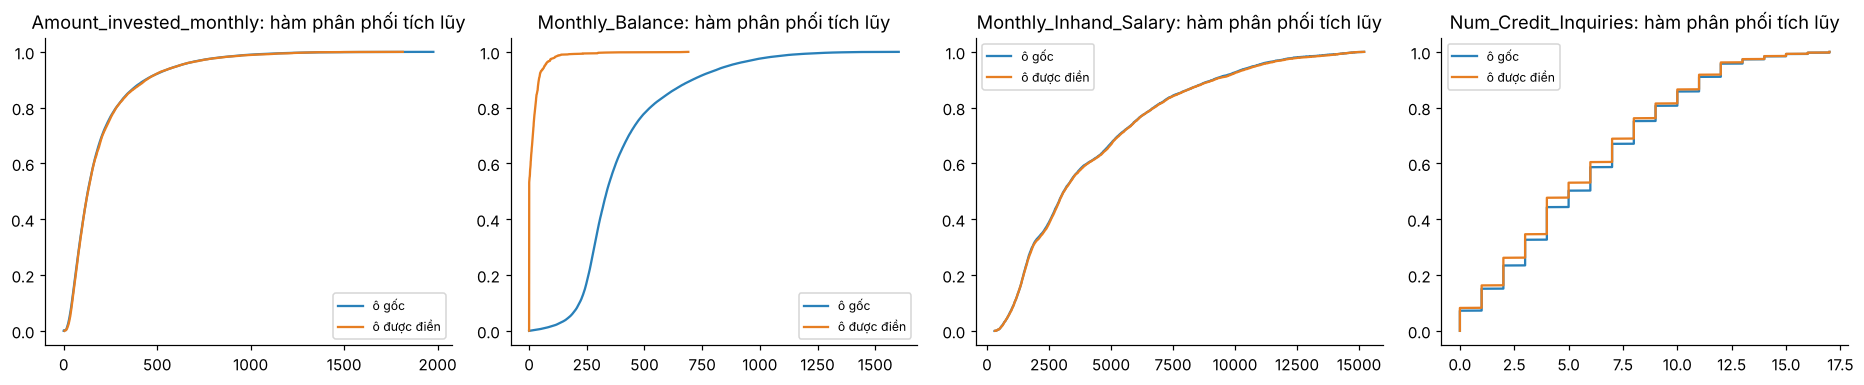

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for a, col in zip(ax, ['Amount_invested_monthly', 'Monthly_Balance', 'Monthly_Inhand_Salary', 'Num_Credit_Inquiries']):
    was_filled = d3[col].isna()
    for mask, label, color in [(~was_filled, 'ô gốc', '#2980b9'), (was_filled, 'ô được điền', '#e67e22')]:
        values = np.sort(clean.loc[mask, col].values)
        a.plot(values, np.arange(1, len(values) + 1) / len(values), label=label, color=color)
    a.set_title(col + ': hàm phân phối tích lũy')
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

Mười một trong mười hai cột có phân phối của ô được điền gần như trùng với ô gốc (KS không quá 0,08) và độ lệch chuẩn gần bằng nhau, nghĩa là cách điền không làm giá trị co cụm về trung bình. Điều này đúng cả với các cột điền theo giá trị gần nhất hoặc trung vị của khách (lương, thu nhập, lãi suất, số tài khoản) lẫn `Amount_invested_monthly` (điền bằng mô hình).

Ngoại lệ cần xem kỹ là `Monthly_Balance`. KS lớn hơn 0,9, ô được điền khác hẳn ô gốc (trung vị 0 so với khoảng 337, độ lệch chuẩn 42 so với 214). Có hai khả năng: mô hình điền bị sai, hoặc các ô thiếu thật sự thuộc một nhóm khách khác. Phải phân biệt hai khả năng này trước khi kết luận.

In [4]:
# (a) Các dòng bị thiếu Monthly_Balance có giống các dòng còn lại không?
balance_missing = d3['Monthly_Balance'].isna()
behaviour = raw['Payment_Behaviour']

def compare(measure):
    """Giá trị của `measure` ở hai nhóm dòng: còn Monthly_Balance và bị thiếu Monthly_Balance."""
    return [measure(~balance_missing), measure(balance_missing)]

table_a = pd.DataFrame({
    'trung vị lương tháng': compare(lambda m: clean.loc[m, 'Monthly_Inhand_Salary'].median()),
    'trung vị đầu tư tháng': compare(lambda m: clean.loc[m, 'Amount_invested_monthly'].median()),
    '% dòng "Low_spent_Small_value"': compare(lambda m: (behaviour[m] == 'Low_spent_Small_value_payments').mean() * 100),
    '% dòng "High_spent_*"': compare(lambda m: behaviour[m].str.startswith('High').mean() * 100),
    '% nhãn Poor': compare(lambda m: (clean.loc[m, 'Credit_Score'] == 'Poor').mean() * 100),
    '% nhãn Standard': compare(lambda m: (clean.loc[m, 'Credit_Score'] == 'Standard').mean() * 100),
    '% nhãn Good': compare(lambda m: (clean.loc[m, 'Credit_Score'] == 'Good').mean() * 100),
}, index=['dòng còn Monthly_Balance', f'dòng bị thiếu (n={int(balance_missing.sum()):,})']).round(1)
table_a

,trung vị lương tháng,trung vị đầu tư tháng,"% dòng ""Low_spent_Small_value""","% dòng ""High_spent_*""",% nhãn Poor,% nhãn Standard,% nhãn Good
dòng còn Monthly_Balance,3058.6,127.4,24.9,43.1,29.0,53.2,17.8
"dòng bị thiếu (n=1,209)",6705.1,750.8,73.0,0.7,28.8,50.6,20.6


Các dòng bị thiếu không phải một mẫu ngẫu nhiên: lương trung vị gấp đôi (khoảng 6.700 so với 3.100), tiền đầu tư cao hơn nhiều, và phần lớn thuộc nhóm chi tiêu thấp (73% là "Low_spent_Small_value" so với 25%, chỉ khoảng 1% là "High_spent" so với 43%). Nghĩa là việc thiếu dữ liệu phụ thuộc vào các cột khác (ít nhất là kiểu MAR), không phải thiếu hoàn toàn ngẫu nhiên (MCAR). Vì thế so với toàn bộ ô gốc là không công bằng, phải so ở cùng vùng đặc trưng. Ta làm hai phép kiểm tra:
1. Che giá trị chỉ trong vùng lương cao (nơi các ô thiếu tập trung) để xem mô hình điền còn chính xác không.
2. So giá trị đã điền với các dòng gốc giống nhất (láng giềng gần nhất theo lương, tiền đầu tư, EMI và mức chi tiêu).

In [5]:
# (b) Che giá trị chỉ trong vùng lương cao (trên 6000 mỗi tháng), so sánh điền theo giá trị và điền theo tỷ lệ
salary = cc.fill_numeric(d3, 'Monthly_Inhand_Salary', 'nearest')
sd = d3['Monthly_Balance'].std()
rows = []
for seed in (0, 1, 2):
    rng = np.random.default_rng(seed)
    known = d3.index[d3['Monthly_Balance'].notna()]
    hidden = rng.choice(known, size=int(0.1 * len(known)), replace=False)
    masked = d3.copy()
    masked.loc[hidden, 'Monthly_Balance'] = np.nan
    high_salary = salary.loc[hidden] > 6000
    for strategy in ['cust_median', 'model', 'model_ratio']:
        filled = cc.fill_numeric(masked, 'Monthly_Balance', strategy).loc[hidden]
        error = (d3.loc[hidden, 'Monthly_Balance'] - filled).abs() / sd
        rows.append({'cách điền': strategy, 'seed': seed,
                     'NMAE, lương <= 6000': error[~high_salary].mean(),
                     'NMAE, lương > 6000': error[high_salary].mean(),
                     'số ô lương cao': int(high_salary.sum())})

trials = pd.DataFrame(rows)
print(f'Mỗi lần che, số ô nằm trong vùng lương cao trung bình: {trials["số ô lương cao"].mean():.0f}')
by_salary = trials.groupby('cách điền').mean().drop(columns=['seed', 'số ô lương cao'])
by_salary.loc[['cust_median', 'model', 'model_ratio']].round(3)

Mỗi lần che, số ô nằm trong vùng lương cao trung bình: 2419


,"NMAE, lương <= 6000","NMAE, lương > 6000"
cách điền,,
cust_median,0.282,0.919
model,0.070,0.154
model_ratio,0.055,0.136


In [6]:
# (c) So với các dòng gốc giống nhất: với mỗi ô Monthly_Balance được điền, lấy trung vị của 20 dòng gốc gần nhất
#     (theo lương, tiền đầu tư, EMI đã chuẩn hóa, và cùng nhóm chi tiêu thấp hoặc cao) rồi xem giá trị điền nằm trên hay dưới.
NEIGHBOUR_COLS = ['Monthly_Inhand_Salary', 'Amount_invested_monthly', 'Total_EMI_per_month']
space = clean[NEIGHBOUR_COLS].copy()
space['low_spender'] = clean['Payment_Behaviour'].str.startswith('Low').astype(float) * 3000
space = (space - space.mean()) / space.std()

balance = clean['Monthly_Balance'].values
observed_rows = np.where(~balance_missing.values)[0]
filled_rows = np.where(balance_missing.values)[0]

nn = NearestNeighbors(n_neighbors=20).fit(space.iloc[observed_rows])
_, neighbours = nn.kneighbors(space.iloc[filled_rows])
neighbour_median = np.median(balance[observed_rows][neighbours], axis=1)
imputed = balance[filled_rows]

# Đối chứng: làm đúng thủ tục đó trên 1.500 dòng gốc đã biết đáp án, để xem phép so láng giềng có tự lệch không
test_rows = np.random.default_rng(0).choice(observed_rows, 1500, replace=False)
rest_rows = np.setdiff1d(observed_rows, test_rows)
nn_check = NearestNeighbors(n_neighbors=20).fit(space.iloc[rest_rows])
_, neighbours_check = nn_check.kneighbors(space.iloc[test_rows])
neighbour_median_check = np.median(balance[rest_rows][neighbours_check], axis=1)
truth_check = balance[test_rows]

print(f'Ô được điền: trung vị giá trị điền = {np.median(imputed):.1f} | trung vị láng giềng gốc = {np.median(neighbour_median):.1f}')
print(f'Tỷ lệ ô được điền thấp hơn láng giềng gốc: {np.mean(imputed < neighbour_median):.1%}')
print(f'(đối chứng) với dòng gốc đã biết đáp án, tỷ lệ đáp án thấp hơn láng giềng: {np.mean(truth_check < neighbour_median_check):.1%}, '
      f'nên bản thân phép so láng giềng không bị lệch')

Ô được điền: trung vị giá trị điền = 0.0 | trung vị láng giềng gốc = 44.5
Tỷ lệ ô được điền thấp hơn láng giềng gốc: 97.1%
(đối chứng) với dòng gốc đã biết đáp án, tỷ lệ đáp án thấp hơn láng giềng: 47.9%, nên bản thân phép so láng giềng không bị lệch


In [7]:
# (d) Mức sàn: dữ liệu gốc không có số dư nhỏ hơn hoặc bằng 0, nhưng mô hình dự đoán dưới 0 cho nhiều ô thiếu (đã chặn ở 0)
original_balance = clean.loc[~balance_missing, 'Monthly_Balance']
filled_balance = clean.loc[balance_missing, 'Monthly_Balance']
print(f'Ô gốc: nhỏ nhất = {original_balance.min():.4f} | số ô <= 0: {(original_balance <= 0).sum()} | '
      f'số ô < 5: {(original_balance < 5).sum()} ({(original_balance < 5).mean():.2%})')
print(f'Ô được điền: {(filled_balance == 0).mean():.1%} nằm đúng ở mức sàn 0 (mô hình dự đoán số dư <= 0), '
      f'{(filled_balance < 5).mean():.1%} nhỏ hơn 5')

Ô gốc: nhỏ nhất = 0.0078 | số ô <= 0: 0 | số ô < 5: 51 (0.05%)
Ô được điền: 52.6% nằm đúng ở mức sàn 0 (mô hình dự đoán số dư <= 0), 58.1% nhỏ hơn 5


Kết luận về `Monthly_Balance` (cần nói rõ khi báo cáo):
- Ở vùng lương cao sai số của mô hình điền lớn hơn khoảng 2 đến 2,5 lần so với vùng lương thấp, nhưng vẫn nhỏ hơn nhiều so với cách dùng trung vị của khách (bảng (b), 0,136 so với 0,919). Điền theo tỷ lệ so với lương (`model_ratio`) tốt hơn điền thẳng giá trị (`model`) ở cả hai vùng.
- Khoảng cách phân phối lớn (KS trên 0,9) chủ yếu do các ô thiếu thuộc một nhóm khách khác (lương cao, đầu tư nhiều, chi tiêu thấp), không phải do mô hình làm méo các giá trị bình thường.
- Tuy vậy, ở các dòng đó mô hình dự đoán số dư bằng hoặc dưới 0 cho hơn một nửa số ô (bị chặn ở 0), trong khi dữ liệu gốc không có số dư nào nhỏ hơn hoặc bằng 0 (nhỏ nhất khoảng 0,008, chỉ khoảng 0,05% ô dưới 5). Giá trị điền cũng thấp hơn các dòng gốc giống nhất ở gần như mọi ô, trong khi phép đối chứng cho thấy cách so này không tự lệch. Dấu hiệu này phù hợp với thiếu không ngẫu nhiên (MNAR): số dư có thể bị bỏ trống chính vì nó nhỏ hơn hoặc bằng 0 (khách chi tiêu và đầu tư hết lương).
- Đây là giả thuyết, không phải kết luận. Dữ liệu không có đáp án thật cho các ô thiếu nên không kiểm chứng được, và sai số thật của các giá trị điền ở nhóm này cũng không đo được.
- Phạm vi ảnh hưởng nhỏ: khoảng 1,2% số dòng (khoảng 0,6% số dòng nằm đúng ở mức sàn), một cột trong 21 cột, và tỷ lệ ba nhãn ở các dòng này gần với các dòng còn lại (bảng (a)). Phần phân tích lỗi ở notebook 4 sẽ kiểm tra mô hình có sai nhiều hơn ở các dòng này không.

Kết luận chung của mục 3.1: điền thiếu không làm co cụm phân phối ở 11 trong 12 cột. Riêng `Monthly_Balance` có cấu trúc thiếu đặc biệt (nghi MNAR) và được ghi vào phần hạn chế.

Kiểm tra cuối: việc điền có tự tạo ra tín hiệu nhãn giả không? Nếu quan hệ với nhãn ở ô được điền khác hẳn ô gốc thì cách điền đã làm méo dữ liệu. Ta so tương quan Spearman với nhãn (Poor < Standard < Good):

In [8]:
rank = clean.Credit_Score.map(LABEL_RANK)
rows = []
for col in ['Amount_invested_monthly', 'Monthly_Balance', 'Monthly_Inhand_Salary', 'Num_Credit_Inquiries',
            'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Total_EMI_per_month', 'Interest_Rate', 'Num_Bank_Accounts']:
    was_filled = d3[col].isna()
    rows.append({'cột': col,
                 'Spearman (ô gốc)': round(stats.spearmanr(clean.loc[~was_filled, col], rank[~was_filled])[0], 3),
                 'Spearman (ô được điền)': round(stats.spearmanr(clean.loc[was_filled, col], rank[was_filled])[0], 3)})
spearman_table = pd.DataFrame(rows).set_index('cột')
spearman_table['chênh lệch'] = (spearman_table.iloc[:, 1] - spearman_table.iloc[:, 0]).round(3)
spearman_table

,Spearman (ô gốc),Spearman (ô được điền),chênh lệch
cột,,,
Amount_invested_monthly,0.126,0.124,-0.002
Monthly_Balance,0.225,-0.008,-0.233
Monthly_Inhand_Salary,0.203,0.205,0.002
Num_Credit_Inquiries,-0.438,-0.454,-0.016
Num_of_Delayed_Payment,-0.362,-0.395,-0.033
Changed_Credit_Limit,-0.157,-0.143,0.014
Total_EMI_per_month,-0.083,-0.096,-0.013
Interest_Rate,-0.481,-0.514,-0.033
Num_Bank_Accounts,-0.387,-0.343,0.044


Ở tám cột đầu của bảng, hệ số của ô được điền cùng dấu và gần bằng ô gốc, lệch nhiều nhất 0,044 (`Num_Bank_Accounts`, ô được điền yếu hơn). Có vài cột ô được điền mạnh hơn một chút (`Interest_Rate`, `Num_of_Delayed_Payment`, chênh khoảng 0,03). Mức chênh này nhỏ. Nếu nhãn lọt vào quá trình điền thì ô được điền sẽ tương quan với nhãn mạnh hơn nhiều, mà pipeline cũng không hề dùng nhãn.

`Monthly_Balance` là ngoại lệ (khoảng 0 ở ô được điền so với 0,22 ở ô gốc). Hơn một nửa số ô được điền cùng bằng 0 nên hạng bị trùng và hệ số này gần như không còn ý nghĩa. Nó phản ánh nhóm khách đặc biệt đã phân tích ở trên, không phải nhãn lọt vào. Kết luận: việc điền thiếu không tạo ra tín hiệu nhãn giả đáng kể.

## 3.2 Quan hệ với nhãn trước và sau khi làm sạch
So sánh độ lớn hiệu ứng (ε² Kruskal–Wallis cho cột số, Cramér's V cho cột phân loại) giữa:
- trước: giá trị hợp lệ của dữ liệu gốc, mỗi đặc trưng chỉ dùng các dòng không lỗi (kết quả đã lưu ở notebook 1, mục 1.7),
- sau: dữ liệu sạch, đủ 100.000 dòng.

In [9]:
before_num = pd.read_csv('../data/reports/eda_effect_numeric_before.csv', index_col=0)
after_num = effect_numeric(clean, [c for c in before_num.index if c in clean.columns])

compare_num = pd.DataFrame({'ε² trước': before_num['ε² (Kruskal)'], 'Spearman trước': before_num['Spearman với nhãn'],
                            'ε² sau': after_num['ε² (Kruskal)'], 'Spearman sau': after_num['Spearman với nhãn']})
compare_num['ε² thay đổi (%)'] = ((compare_num['ε² sau'] / compare_num['ε² trước'] - 1) * 100).round(1)
compare_num.sort_values('ε² sau', ascending=False).round(4)

,ε² trước,Spearman trước,ε² sau,Spearman sau,ε² thay đổi (%)
đặc trưng,,,,,
Interest_Rate,0.2334,-0.4809,0.2341,-0.4816,0.3
Delay_from_due_date,0.1946,-0.4379,0.1946,-0.4379,0.0
Outstanding_Debt,0.1940,-0.4338,0.1940,-0.4338,0.0
Num_Credit_Inquiries,0.1920,-0.4379,0.1925,-0.4385,0.3
Num_Bank_Accounts,0.1575,-0.3874,0.1571,-0.3867,-0.3
Num_Credit_Card,0.1487,-0.3850,0.1494,-0.3859,0.4
Num_of_Delayed_Payment,0.1439,-0.3617,0.1466,-0.3650,1.9
Num_of_Loan,0.1248,-0.3531,0.1256,-0.3542,0.7
Changed_Credit_Limit,0.0534,-0.1573,0.0535,-0.1570,0.3


,Cramér V trước,Cramér V sau,thay đổi (%)
Credit_Mix,0.4022,0.4499,11.9
Month,0.0318,0.0318,0.0
Occupation,0.0292,0.0301,3.1
Payment_Behaviour,0.0846,0.0846,0.0
Payment_of_Min_Amount,0.3132,0.3132,0.0


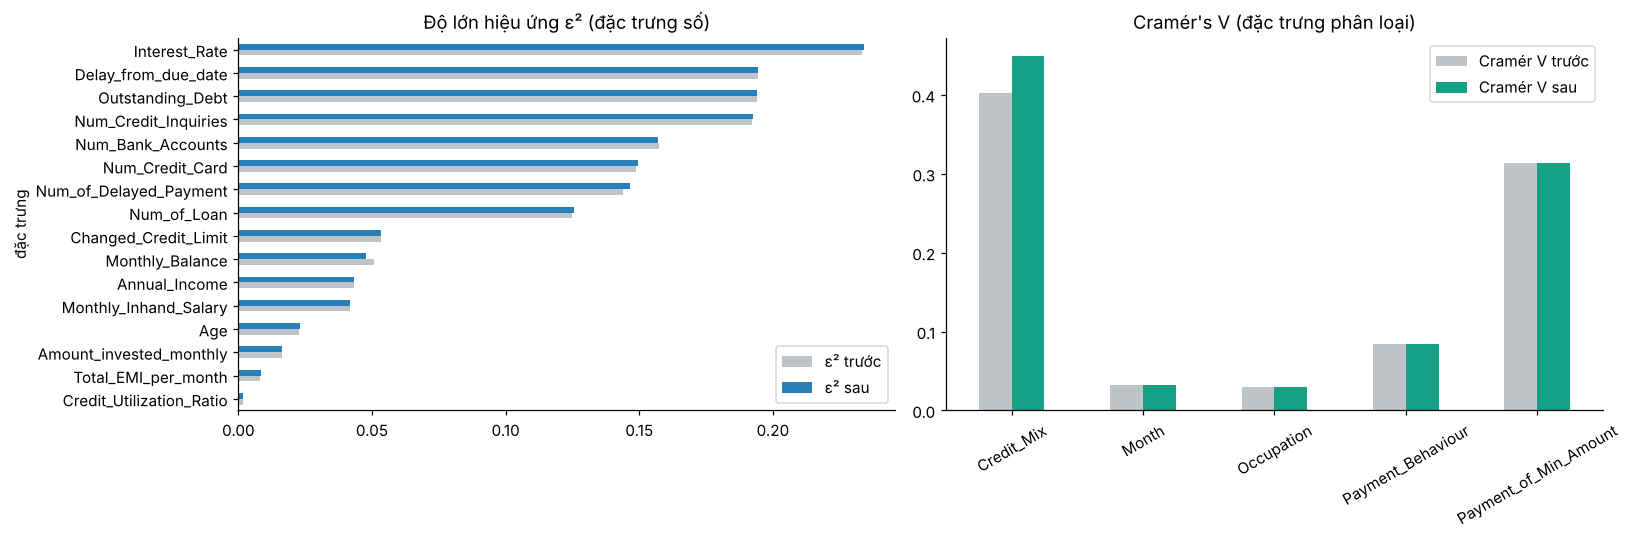

In [10]:
before_cat = pd.read_csv('../data/reports/eda_effect_categorical_before.csv', index_col=0)
after_cat = pd.Series({c: cramers_v(clean[c], clean.Credit_Score)
                       for c in ['Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour', 'Occupation', 'Month']})
compare_cat = pd.DataFrame({'Cramér V trước': before_cat['Cramér V'], 'Cramér V sau': after_cat}).round(4)
compare_cat['thay đổi (%)'] = ((compare_cat['Cramér V sau'] / compare_cat['Cramér V trước'] - 1) * 100).round(1)
display(compare_cat)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
compare_num.sort_values('ε² sau')[['ε² trước', 'ε² sau']].plot(kind='barh', ax=ax[0], color=['#bdc3c7', '#2980b9'])
ax[0].set_title('Độ lớn hiệu ứng ε² (đặc trưng số)')
compare_cat[['Cramér V trước', 'Cramér V sau']].plot(kind='bar', ax=ax[1], color=['#bdc3c7', '#16a085'], rot=30)
ax[1].set_title("Cramér's V (đặc trưng phân loại)")
plt.tight_layout()
plt.show()

Sau khi làm sạch:
- Thứ tự mức liên quan giữ nguyên (lãi suất, độ trễ, nợ, truy vấn tín dụng vẫn đứng đầu), nên không quan hệ thật nào bị xóa.
- Phần lớn các cột đổi dưới 2% (`Num_of_Delayed_Payment` tăng nhiều nhất, 1,9%). Hai ngoại lệ: `Credit_Mix` có Cramér V tăng từ 0,40 lên 0,45 (+11,9%), và `Monthly_Balance` giảm 5,5% do các ô được điền gần như không còn tương quan với nhãn (đã nói ở 3.1).
- Với `Credit_Mix`, cột "trước" chỉ tính trên các dòng có giá trị hợp lệ (khoảng 80% số dòng), còn 20% dòng mang giá trị giả `_` nay được điền lại bằng giá trị của chính khách đó ở các tháng khác. Mình không tách riêng được phần tăng nào do điền lại và phần nào do đổi tập dòng.
- Các cột vốn không liên quan (`Occupation`, `Month`) vẫn không liên quan, nên việc làm sạch không tạo ra quan hệ giả.

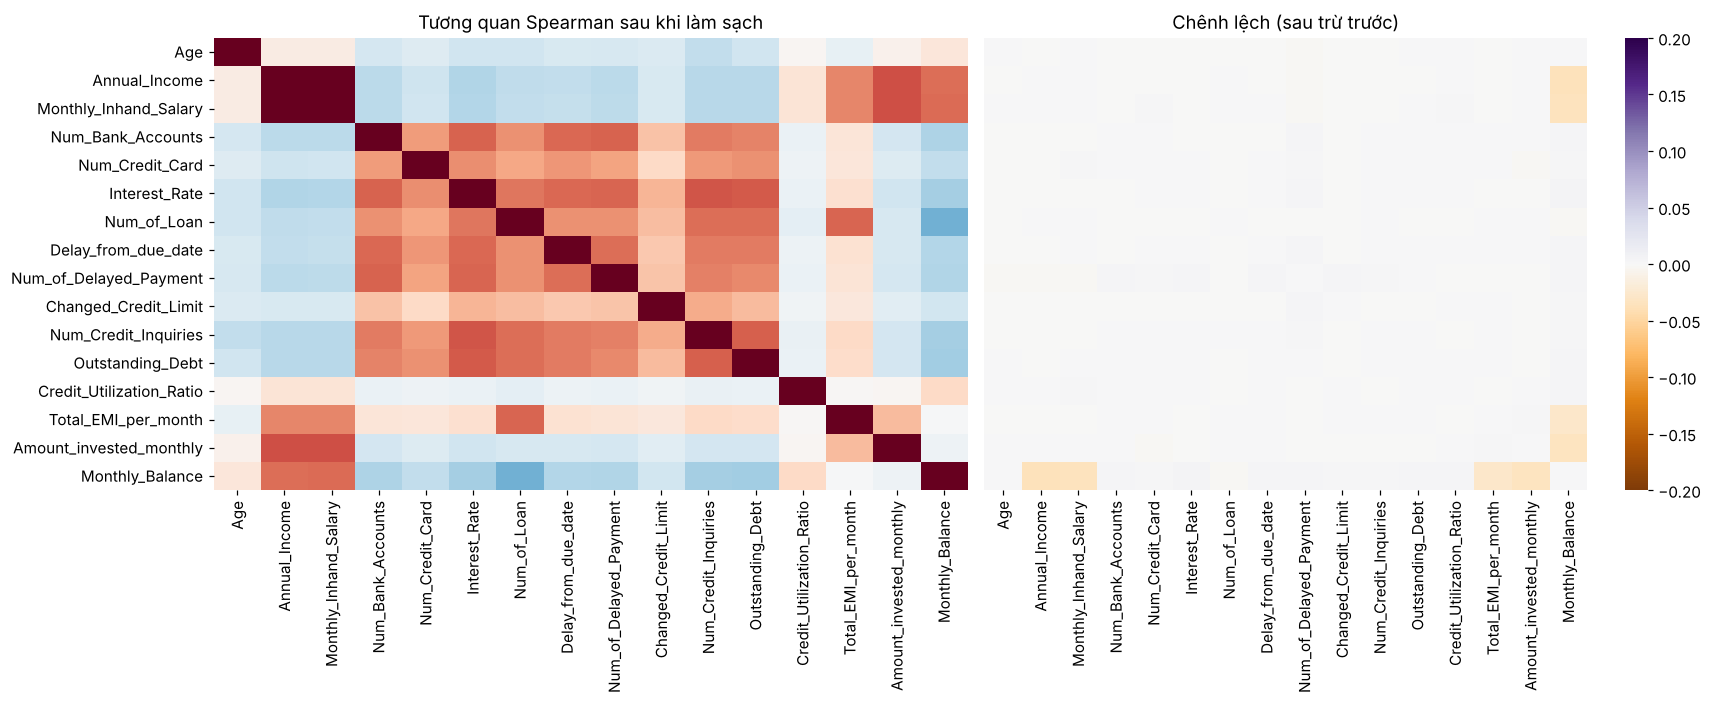

Chênh lệch tuyệt đối trung bình giữa 120 cặp tương quan: 0.002 | lớn nhất: 0.036


In [11]:
# Cấu trúc tương quan giữa các đặc trưng có được giữ không?
NUM_COLS = ['Age', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate',
            'Num_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
            'Num_Credit_Inquiries', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Total_EMI_per_month',
            'Amount_invested_monthly', 'Monthly_Balance']

corr_before = d3[NUM_COLS].corr(method='spearman')
corr_after = clean[NUM_COLS].corr(method='spearman')
difference = corr_after - corr_before

fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
sns.heatmap(corr_after, cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax[0], cbar=False, xticklabels=True, yticklabels=True)
ax[0].set_title('Tương quan Spearman sau khi làm sạch')
sns.heatmap(difference, cmap='PuOr', center=0, vmin=-.2, vmax=.2, ax=ax[1], xticklabels=True, yticklabels=False)
ax[1].set_title('Chênh lệch (sau trừ trước)')
plt.tight_layout()
plt.show()

pairs = difference.values[np.triu_indices(len(NUM_COLS), 1)]
print(f'Chênh lệch tuyệt đối trung bình giữa {len(pairs)} cặp tương quan: {np.abs(pairs).mean():.3f} | lớn nhất: {np.abs(pairs).max():.3f}')

Tương quan giữa các đặc trưng thay đổi rất ít (trung bình 0,002, lớn nhất 0,036), nên cấu trúc phụ thuộc lẫn nhau được giữ nguyên.

## 3.3 Tạo đặc trưng
Dữ liệu sạch đã đủ để chạy mô hình, nhưng còn hai nguồn thông tin mà các cột thô chưa diễn đạt: quan hệ tài chính (các tỷ số) và cấu trúc theo thời gian của từng khách. Có 5 nhóm đặc trưng, mỗi nhóm có lý do riêng:

| Nhóm | Đặc trưng | Lý do |
|---|---|---|
| RATIO | `Debt_to_Income`, `EMI_to_Salary`, `Invest_to_Salary`, `Balance_to_Salary`, `Implied_Spend_Ratio`, `Debt_per_Loan`, `Has_Loan` | Nợ 3.000 là gánh nặng với người thu 20.000 một năm nhưng nhẹ với người thu 150.000, nên mô hình cần tỷ lệ chứ không chỉ số tuyệt đối. `Implied_Spend_Ratio` là phần lương không giải thích được bằng EMI, đầu tư và số dư, coi như tiền đã chi tiêu |
| LOAN | 9 cột `Loan_*` | `Type_of_Loan` là chuỗi nhiều giá trị. Tách ra để mô hình dùng được từng loại vay (ví dụ vay "Payday" có thể rủi ro hơn "Home Equity") |
| PB_SPLIT | `Spend_Level`, `Payment_Size` | `Payment_Behaviour` ghép hai ý (mức chi tiêu và độ lớn khoản trả). Tách ra để các tổ hợp chia sẻ thống kê cho nhau |
| LAG (chỉ dùng quá khứ) | `*_prev`, `*_delta`, `*_expmean` cho độ trễ, số lần trả chậm, tỷ lệ dùng hạn mức, số lần truy vấn | Xu hướng: tháng này có tệ hơn tháng trước không. Chỉ dùng tháng hiện tại và các tháng trước, nên dùng được khi dự đoán trong thực tế |
| CUST_AGG (nhìn lại 8 tháng) | trung bình và độ lệch chuẩn trên 8 tháng của 7 chỉ số, tỷ lệ tháng không trả mức tối thiểu | Hành vi đặc trưng của khách, ổn định hơn một tháng đơn lẻ. Nhóm này dùng cả các tháng sau, nên chỉ hợp lệ khi đã biết đủ 8 tháng |

Phải tách LAG và CUST_AGG để không báo cáo một kết quả mà thực tế không thể có (chưa biết các tháng tương lai).

In [12]:
show_code(cf, 'add_ratio_features', 'add_loan_flags', 'add_payment_split', 'add_lag_features',
          'add_customer_features', 'build_features')

def add_ratio_features(d):
    """Các tỷ số tài chính trong từng dòng. Mẫu số được chặn dưới ở 1 để không chia cho 0."""
    d = d.copy()
    salary = d['Monthly_Inhand_Salary'].clip(lower=1)
    d['Debt_to_Income'] = d['Outstanding_Debt'] / d['Annual_Income']
    d['EMI_to_Salary'] = d['Total_EMI_per_month'] / salary
    d['Invest_to_Salary'] = d['Amount_invested_monthly'] / salary
    d['Balance_to_Salary'] = d['Monthly_Balance'] / salary
    # phần lương còn lại sau khi trừ EMI, tiền đầu tư và số dư cuối tháng, coi như tiền đã chi tiêu
    d['Implied_Spend_Ratio'] = (salary - d['Total_EMI_per_month'] - d['Amount_invested_monthly']
                                - d['Monthly_Balance']) / salary
    d['Debt_per_Loan'] = d['Outstanding_Debt'] / d['Num_of_Loan'].clip(lower=1)
    d['Has_Loan'] = (d['Num_of_Loan'] > 0).astype(int)
    return d

def add_loan_flags(d):
    """Mỗi loại khoản vay thành một cột 0/1 (khách có loại vay đó hay không)."""
    d = d.copy()
    types_of = {u: set(

In [13]:
feat = cf.build_features(clean)
new_cols = [c for g in ['RATIO', 'LOAN', 'PB_SPLIT', 'LAG', 'CUST_AGG'] for c in cf.FEATURE_GROUPS[g]]
print(f'Bảng đặc trưng: {feat.shape} (thêm {len(new_cols)} cột so với dữ liệu sạch)')
print(pd.Series({g: len(v) for g, v in cf.FEATURE_GROUPS.items()}, name='số cột').to_frame().T.to_string())

new_numeric = [c for c in new_cols if c not in cf.CATEGORICAL]
assert np.isfinite(feat[new_numeric].values).all(), 'Có NaN hoặc inf trong đặc trưng mới'
print('Không có NaN hay inf trong các đặc trưng mới')
feat[cf.RATIO + cf.CUST_AGG[:4]].describe().T[['min', '25%', '50%', '75%', 'max']].round(3)

Bảng đặc trưng: (100000, 74) (thêm 45 cột so với dữ liệu sạch)
        BASE  RATIO  LOAN  PB_SPLIT  LAG  CUST_AGG
số cột    21      7     9         2   12        15
Không có NaN hay inf trong các đặc trưng mới


,min,25%,50%,75%,max
Debt_to_Income,0.000,0.010,0.028,0.070,0.683
EMI_to_Salary,0.000,0.012,0.024,0.040,0.225
Invest_to_Salary,0.000,0.025,0.044,0.075,0.154
Balance_to_Salary,0.000,0.080,0.115,0.179,0.876
Implied_Spend_Ratio,-0.055,0.726,0.812,0.855,0.888
Debt_per_Loan,0.049,215.121,375.587,617.916,1498.410
Has_Loan,0.000,1.000,1.000,1.000,1.000
Delay_from_due_date_cust_mean,-2.000,9.875,17.875,28.000,63.250
Delay_from_due_date_cust_std,0.000,1.061,1.642,2.078,3.926
Num_of_Delayed_Payment_cust_mean,0.000,9.000,13.750,18.250,26.375


## 3.4 Đặc trưng mới có thật sự hữu ích không?
Tạo đặc trưng thì dễ, quan trọng là đo xem nó có ích không. Ta dùng ba phép đo độc lập:
1. Độ lớn hiệu ứng ε² (Kruskal): ba nhãn tách nhau bao nhiêu theo đặc trưng đó.
2. Mutual information (MI) với nhãn: bắt được cả quan hệ không tuyến tính.
3. Độ trùng lặp với các đặc trưng gốc: đặc trưng mới mà tương quan gần 1 với một cột gốc thì không thêm thông tin.

In [14]:
all_numeric = cf.BASE_NUM + new_numeric

def group_of(col):
    return next((g for g, cols in cf.FEATURE_GROUPS.items() if col in cols), '?')

effect = effect_numeric(feat, all_numeric)
effect['nhóm'] = [group_of(c) for c in effect.index]
effect = effect.sort_values('ε² (Kruskal)', ascending=False)
effect[['ε² (Kruskal)', 'Spearman với nhãn', 'nhóm']].round(4).head(25)

,ε² (Kruskal),Spearman với nhãn,nhóm
đặc trưng,,,
Interest_Rate,0.2341,-0.4816,BASE
Num_Credit_Inquiries_expmean,0.2113,-0.4595,LAG
Num_Credit_Inquiries_cust_mean,0.2066,-0.4545,CUST_AGG
MinPay_No_share,0.2059,0.4175,CUST_AGG
Delay_from_due_date_cust_mean,0.1980,-0.4416,CUST_AGG
Num_Credit_Inquiries_prev,0.1977,-0.4443,LAG
Delay_from_due_date_expmean,0.1973,-0.4409,LAG
Delay_from_due_date_prev,0.1952,-0.4387,LAG
Delay_from_due_date,0.1946,-0.4379,BASE


Về mutual information: mỗi khách có 8 dòng gần giống nhau, và với cột chỉ có một giá trị cho mỗi khách (thu nhập, dư nợ, các thống kê theo khách) thì giá trị đó gần như là mã của khách. Vì nhãn của cùng một khách khá ổn định, bộ ước lượng MI sẽ thấy "giá trị giống nhau thì nhãn giống nhau" và cho điểm rất cao, dù chỉ là do các dòng không độc lập. Ta kiểm tra điều này bằng cách tính MI trên hai cách lấy mẫu:
- lấy tất cả 8 dòng của 3.750 khách (30.000 dòng),
- lấy đúng một dòng ngẫu nhiên cho mỗi khách (12.500 dòng).

In [15]:
rng = np.random.default_rng(0)
sample_customers = rng.choice(feat.Customer_ID.unique(), size=3750, replace=False)
all_rows = feat[feat.Customer_ID.isin(sample_customers)]
one_row = feat.groupby('Customer_ID').sample(1, random_state=0)

def mutual_info(d, cols):
    return pd.Series(mutual_info_classif(d[cols], d.Credit_Score, random_state=0), index=cols)

demo_cols = ['Annual_Income', 'Outstanding_Debt', 'Interest_Rate', 'Delay_from_due_date', 'Credit_Utilization_Ratio']
pd.DataFrame({'MI, 8 dòng mỗi khách (3.750 khách)': mutual_info(all_rows, demo_cols),
              'MI, 1 dòng mỗi khách (12.500 khách)': mutual_info(one_row, demo_cols)}).round(3)

,"MI, 8 dòng mỗi khách (3.750 khách)","MI, 1 dòng mỗi khách (12.500 khách)"
Annual_Income,0.626,0.060
Outstanding_Debt,0.625,0.150
Interest_Rate,0.183,0.170
Delay_from_due_date,0.124,0.131
Credit_Utilization_Ratio,0.000,0.006


`Annual_Income` và `Outstanding_Debt` có MI cao bất thường khi lấy 8 dòng mỗi khách, rồi tụt mạnh khi chỉ lấy 1 dòng mỗi khách. Còn `Delay_from_due_date` (thay đổi theo tháng) hầu như không đổi. Vậy cách lấy 8 dòng làm điểm MI của các cột "mã khách" bị thổi phồng. Từ đây ta dùng cách lấy 1 dòng mỗi khách để so sánh các nhóm đặc trưng.

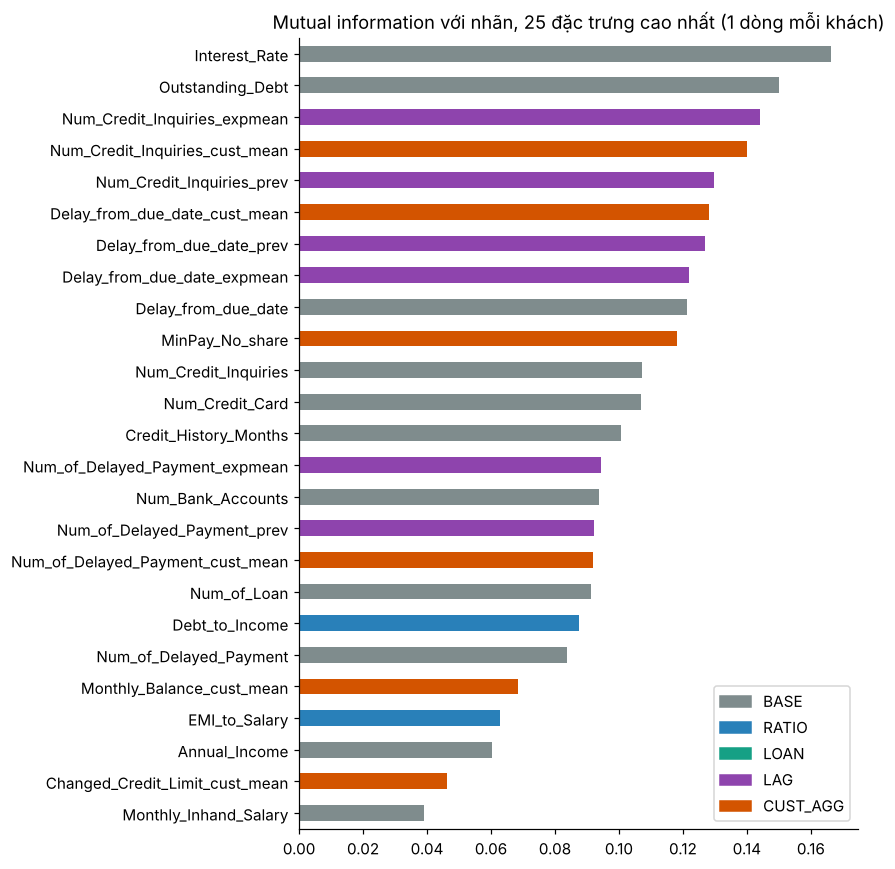

,MI trung bình của nhóm,MI lớn nhất,số cột
BASE,0.0727,0.1664,17
LAG,0.0612,0.1440,12
CUST_AGG,0.0458,0.1401,15
RATIO,0.0339,0.0875,7
LOAN,0.0103,0.0178,9


In [16]:
mi = mutual_info(one_row, all_numeric).sort_values(ascending=False)
mi_group = pd.Series([group_of(c) for c in mi.index], index=mi.index)
GROUP_COLORS = {'BASE': '#7f8c8d', 'RATIO': '#2980b9', 'LOAN': '#16a085', 'LAG': '#8e44ad', 'CUST_AGG': '#d35400'}

fig, ax = plt.subplots(figsize=(8, 8))
top = mi.head(25)[::-1]
top.plot(kind='barh', ax=ax, color=mi_group.map(GROUP_COLORS).head(25)[::-1])
ax.set_title('Mutual information với nhãn, 25 đặc trưng cao nhất (1 dòng mỗi khách)')
ax.legend(handles=[mpatches.Patch(color=color, label=name) for name, color in GROUP_COLORS.items()], loc='lower right')
plt.tight_layout()
plt.show()

pd.DataFrame({'MI trung bình của nhóm': mi.groupby(mi_group).mean().round(4),
              'MI lớn nhất': mi.groupby(mi_group).max().round(4),
              'số cột': mi_group.value_counts()}).sort_values('MI lớn nhất', ascending=False)

In [17]:
# Độ trùng lặp: các cặp đặc trưng có |ρ| > 0,95 mà ít nhất một bên là đặc trưng mới
abs_corr = feat[all_numeric].corr(method='spearman').abs()
upper_pairs = abs_corr.where(np.triu(np.ones(abs_corr.shape, dtype=bool), 1)).stack()
duplicates = upper_pairs[upper_pairs > 0.95].sort_values(ascending=False)
involves_new = [(a in new_numeric) or (b in new_numeric) for a, b in duplicates.index]
duplicates = duplicates[involves_new]
print(f'{len(duplicates)} cặp có |ρ| > 0,95 liên quan đến đặc trưng mới:')
duplicates.round(3).to_frame('|ρ|')

23 cặp có |ρ| > 0,95 liên quan đến đặc trưng mới:


,,|ρ|
Delay_from_due_date_expmean,Delay_from_due_date_cust_mean,0.998
Num_of_Delayed_Payment_expmean,Num_of_Delayed_Payment_cust_mean,0.996
Monthly_Balance_cust_std,Amount_invested_monthly_cust_std,0.994
Delay_from_due_date,Delay_from_due_date_expmean,0.993
Delay_from_due_date_prev,Delay_from_due_date_expmean,0.993
Delay_from_due_date,Delay_from_due_date_cust_mean,0.990
Delay_from_due_date_prev,Delay_from_due_date_cust_mean,0.990
Num_of_Delayed_Payment_prev,Num_of_Delayed_Payment_expmean,0.987
Num_of_Delayed_Payment,Num_of_Delayed_Payment_expmean,0.987
Num_Credit_Inquiries_prev,Num_Credit_Inquiries_expmean,0.984


Kết luận về đặc trưng:
- Theo ε², các đặc trưng theo thời gian (`LAG`) và thống kê 8 tháng (`CUST_AGG`) nằm cùng mức, ngay sau `Interest_Rate`. Điều này hợp lý vì nhãn đổi chậm (xác suất giữ nhãn trên 0,8 mỗi tháng, notebook 1), nên hành vi tích lũy phản ánh nhãn tốt hơn số liệu riêng của một tháng.
- Theo MI (đã sửa bằng cách lấy 1 dòng mỗi khách), `LAG` và `CUST_AGG` cũng sát nhau (MI lớn nhất 0,144 và 0,140) và chỉ thấp hơn một chút so với hai cột gốc mạnh nhất (`Interest_Rate` 0,166, `Outstanding_Debt` 0,150). Vậy nhóm `LAG` cho mức liên hệ đơn lẻ tương đương `CUST_AGG` mà không cần biết các tháng sau. Trong `LAG`, `Num_Credit_Inquiries_expmean` (trung bình lũy kế số lần truy vấn tín dụng) cao nhất.
- `RATIO`: `Debt_to_Income` khá mạnh (ε² 0,16, MI 0,088), các tỷ số còn lại yếu hơn. `LOAN` (cờ loại vay) gần như không liên hệ với nhãn (MI lớn nhất 0,018).
- Mức liên hệ đơn lẻ mạnh không có nghĩa mô hình sẽ tốt hơn. Các đặc trưng mới tương quan rất cao với cột gốc (23 cặp có |ρ| trên 0,95, ví dụ `Delay_from_due_date_expmean` và `Delay_from_due_date` có ρ = 0,993), nên phần lớn thông tin của chúng mô hình đã có. Notebook 4 sẽ đo trực tiếp điều này bằng ablation.
- Các cặp trùng lặp là điều dự kiến (ví dụ trung bình lũy kế của tháng cuối bằng trung bình cả 8 tháng). Mô hình cây không bị ảnh hưởng nhiều, còn Logistic Regression ở notebook 4 có phạt L2 sẵn nên vẫn chạy ổn.

Đóng góp thật của từng nhóm cho mô hình được đo trực tiếp ở notebook 4 (mục ablation nhóm đặc trưng).

## 3.5 Xuất file đặc trưng

In [18]:
feat.to_csv('../data/credit_features.csv', index=False)
print('Đã lưu data/credit_features.csv', feat.shape)
pd.Series({g: ', '.join(v[:4]) + (' ...' if len(v) > 4 else '') for g, v in cf.FEATURE_GROUPS.items()},
          name='ví dụ cột').to_frame()

Đã lưu data/credit_features.csv (100000, 74)


,ví dụ cột
BASE,"Age, Annual_Income, Monthly_Inhand_Salary, Num_Bank_Acco..."
RATIO,"Debt_to_Income, EMI_to_Salary, Invest_to_Salary, Balance..."
LOAN,"Loan_Auto_Loan, Loan_Credit_Builder_Loan, Loan_Debt_Cons..."
PB_SPLIT,"Spend_Level, Payment_Size"
LAG,"Delay_from_due_date_prev, Delay_from_due_date_delta, Del..."
CUST_AGG,"Delay_from_due_date_cust_mean, Delay_from_due_date_cust_..."


## Tổng kết notebook 3

| Câu hỏi | Kết quả |
|---|---|
| Điền thiếu có làm méo phân phối không? | Không ở 11 trong 12 cột (KS nhỏ, độ lệch chuẩn giữ nguyên). Ngoại lệ là `Monthly_Balance`: ô thiếu thuộc nhóm khách khác (lương cao, chi tiêu thấp). Mô hình điền chính xác ở vùng đó nhưng không loại trừ được thiếu không ngẫu nhiên, nên ghi vào phần hạn chế |
| Có tạo tín hiệu nhãn giả không? | Không đáng kể. Tương quan với nhãn ở ô được điền gần bằng ô gốc (lệch nhiều nhất 0,044, trừ `Monthly_Balance` vì nhiều ô cùng bằng 0) |
| Làm sạch có giữ quan hệ thật không? | Có. Thứ tự mức liên quan giữ nguyên, phần lớn cột đổi dưới 2%, riêng `Credit_Mix` tăng rõ (V từ 0,40 lên 0,45) |
| Cấu trúc tương quan có giữ không? | Có, chênh lệch trung bình rất nhỏ |
| Đặc trưng mới có ích không? | Có liên hệ đơn lẻ với nhãn (nhất là nhóm theo thời gian) nhưng trùng nhiều với cột gốc, nên cần đo đóng góp thật cho mô hình ở notebook 4 |

`credit_features.csv` sẵn sàng cho notebook 4.